# Trabajo Práctico 3: Predicción Lineal de Señales de Voz

**22.46 Procesamiento Adaptativo de Señales Aleatorias**

**Grupo 3**

| Integrante | Legajo |
|:-----:|:------------|
| Elisa Fernandez Morales | 69616 |
| Alvaro Martin | 69507 |
| Thomas Michael Spitzner | 69453 |


## 0. Imports

In [11]:
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.io import wavfile
from scipy.signal import resample_poly, correlate, lfilter, freqz, welch, spectrogram, windows
from scipy.linalg import solve_toeplitz
from matplotlib.ticker import MultipleLocator

# Carpetas del proyecto
DIR_GRABACIONES = Path("audio/grabaciones")
DIR_SINTETIZADAS = Path("audio/sintetizadas")
DIR_SINTETIZADAS.mkdir(parents=True, exist_ok=True)

fs = 16000  # frecuencia de muestreo pedida en la consigna

# 1. Grabaciones y Acondicionamiento de Señales

La primera etapa consiste en la adquisición y el preprocesamiento de las señales de audio que servirán como base para los análisis posteriores. Se registraron fonaciones correspondientes a los sonidos **/a/** (vocal abierta sonora) y **/sh/** (fricativa postalveolar sorda), fijando una frecuencia de muestreo uniforme de $f_s = 16\text{ kHz}$ y seleccionando un fragmento representativo de $1\text{ s}$ de duración ($16\,000$ muestras)


## Metodología de adquisición

Las señales se capturaron en formato digital monocanal lineal PCM a $16\text{ kHz}$ con la application RecForge II con un Google Pixel 6. 

Con el propósito de estandarizar la articulación fonética se tomaron como patrones de referencia las grabaciones del Alfabeto Fonético Internacional (IPA):
* **/a/**: [vocal abierta anterior no redondeada](https://en.wikipedia.org/wiki/File:Open_front_unrounded_vowel.ogg) ($[a]$).
* **/sh/**: interpretado como la [fricativa postalveolar sorda](https://en.wikipedia.org/wiki/Voiceless_postalveolar_fricative) ($[\int]$).

In [12]:
# FUNCIÓN PARA LEER EL AUDIO

def cargar_audio(nombre, inicio=0.0, duracion=1):
    # inicio y duracion en segundos (duracion=None -> hasta el final de la grabación)

    with warnings.catch_warnings():
        # los WAV del celular tienen un chunk de metadatos que scipy no entiende (WavFileWarning)
        warnings.simplefilter("ignore", wavfile.WavFileWarning)
        fs, x = wavfile.read(nombre)

    # Si es estéreo, lo pasamos a mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    # Si no está a 16 kHz, lo remuestreamos
    if fs != 16000:

        x = resample_poly(x,16000,fs)
        fs = 16000

    # recortando el tramo pedido: desde "inicio" y, si es especificado, solo "duracion" segundos
    i0 = int(inicio * fs)
    if duracion is not None:
        x = x[i0:i0 + int(duracion * fs)]
    else:
        x = x[i0:]

    # Quitamos la media
    x = x - np.mean(x)

    # Normalizamos
    x = x / np.max(np.abs(x))

    return x

## Selección del intervalo de análisis estacionario

Los registros de audio presentan transitorios iniciales de ataque y silencios previos al establecimiento del régimen de fonación continuo. En consecuencia, no resulta adecuado extraer arbitrariamente el primer segundo del archivo. 

A continuación se grafican las señales completas para identificar visual y cuantitativamente una ventana temporal de $1\text{ s}$ caracterizada por su régimen estacionario (indicada mediante el área sombreada).

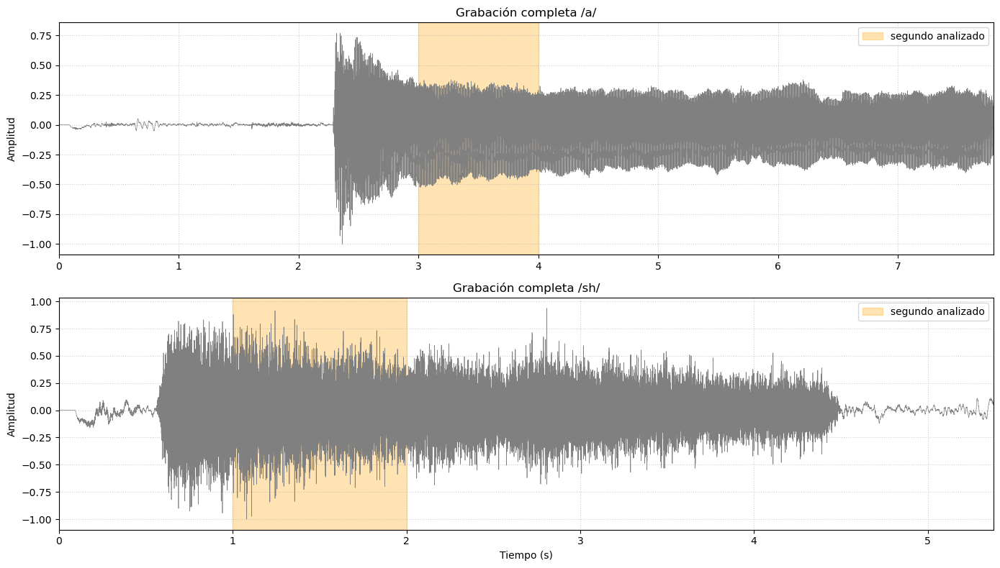

In [13]:
archivos = {"/a/": DIR_GRABACIONES / "a_16k.wav",
            "/sh/": DIR_GRABACIONES / "sh_16k.wav"}

# segundo (en s) donde empieza el tramo de 1 s elegido para cada sonido
inicios = {"/a/": 3.0, "/sh/": 1.0}

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (nombre, archivo) in zip(axes, archivos.items()):
    x_completo = cargar_audio(archivo, duracion=None)
    t = np.arange(len(x_completo)) / fs
    ax.plot(t, x_completo, color="gray", lw=0.5)
    ax.axvspan(inicios[nombre], inicios[nombre] + 1, color="orange", alpha=0.3, label="segundo analizado")
    ax.set_title(f"Grabación completa {nombre}")
    ax.set_ylabel("Amplitud")
    ax.set_xlim(0, t[-1])
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

In [14]:
# CARGAR EL SEGUNDO ELEGIDO DE /a/ Y /sh/ 
a = cargar_audio(archivos["/a/"], inicio=inicios["/a/"])
sh = cargar_audio(archivos["/sh/"], inicio=inicios["/sh/"])


# Para escuchar los tramos que se van a analizar
for nombre, x in [("/a/", a), ("/sh/", sh)]:
    print(f"{nombre} (1 s):")
    ipd.display(ipd.Audio(x, rate=fs))

/a/ (1 s):


/sh/ (1 s):


# Parte 2 (Predicción forward y MSE mínimo $J(M)$)

En este apartado se formula la forward linear prediction. El objetivo consiste en estimar la muestra actual $x[n]$ a partir de una combinación lineal de las $M$ muestras inmediatamente precedentes:

$$\hat{x}[n] = \sum_{k=1}^M a_k\,x[n-k] = a_1 x[n-1] + a_2 x[n-2] + \cdots + a_M x[n-M]$$

donde $x[n]$ representa la señal observada, $\hat{x}[n]$ es la estimación predicha, $M$ denota el orden del predictor y $\mathbf{a} = [a_1, a_2, \dots, a_M]^T$ es el vector de coeficientes del filtro transversal.

La señal de error de predicción hacia adelante se define como la discrepancia entre el valor observado y su estimación:

$$e_f[n] = x[n] - \hat{x}[n] = x[n] - \sum_{k=1}^M a_k\,x[n-k]$$

Bajo el criterio de mínimos cuadrados, se busca determinar el vector $\mathbf{a}$ que minimiza el error cuadrático medio (*Mean Squared Error*, MSE), denominado $J(M)$:

$$J(M) = \mathbb{E}\left\{e_f^2[n]\right\} \approx \frac{1}{N} \sum_{n=0}^{N-1} e_f^2[n]$$

Aplicando el principio de ortogonalidad ($\mathbb{E}\left\{e_f[n]\,x[n-k]\right\} = 0$ para $k = 1, \dots, M$), se arriba a las ecuaciones normales de Yule-Walker:

$$\mathbf{R}\,\mathbf{a} = \mathbf{p}$$

donde $\mathbf{R} \in \mathbb{R}^{M \times M}$ es una matriz de Toeplitz simétrica cuyos elementos están dados por los coeficientes de autocorrelación $R_{ij} = r_x[|i-j|]$, y $\mathbf{p} = [r_x[1], r_x[2], \dots, r_x[M]]^T$ es el vector de correlaciones cruzadas.

Una vez calculados los coeficientes óptimos mediante la resolución del sistema de Toeplitz, el valor del MSE mínimo residual se evalúa analíticamente de forma directa sin necesidad de convolucionar la señal completa:

$$J(M) = r_x[0] - \mathbf{p}^T \mathbf{a}$$


## Interpretación física de los puntos de inflexión ("codos")

La función $J(M)$ es monótona no creciente respecto de $M$. Un **codo** o punto de inflexión en la curva representa una discontinuidad en la derivada de $J(M)$:
* Antes del codo, el incremento de $M$ aporta grados de libertad capaces de modelar dependencias estadísticas significativas de la señal, produciendo una fuerte reducción en $J$.
* Tras el codo, los coeficientes adicionales solo ajustan redundancias menores o ruido de fondo, manteniéndose $J(M)$ en una meseta. La localización de estos codos revela la estructura intrínseca de los mecanismos de generación acústica del fonema.

In [15]:
# FUNCIÓN PARA CALCULAR J(M)

def calcular_J(x, Mmax):

    N = len(x)

    # Autocorrelación
    r = correlate( x, x, mode="full", method="fft")

    centro = N - 1

    r = r[centro:centro + Mmax + 1] / N
    valores_J = []


    for M in range(1, Mmax + 1):
        p = r[1:M+1]
        a = solve_toeplitz((r[:M], r[:M]),p)

        # MSE mínimo
        J = r[0] - np.dot(p, a)

        valores_J.append(J)


    return np.array(valores_J)

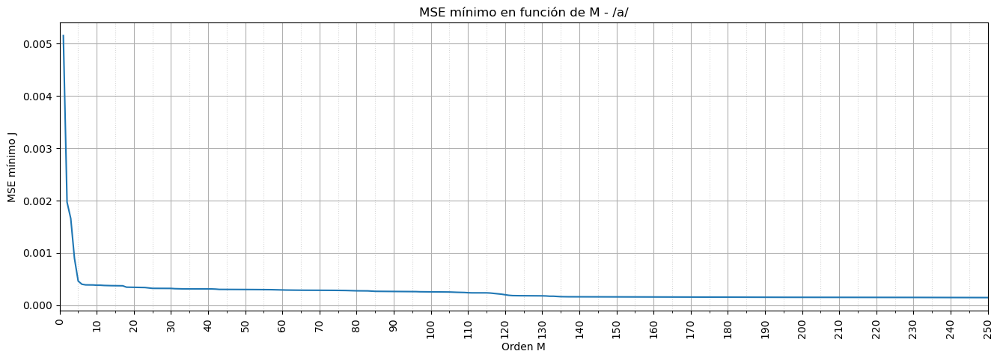

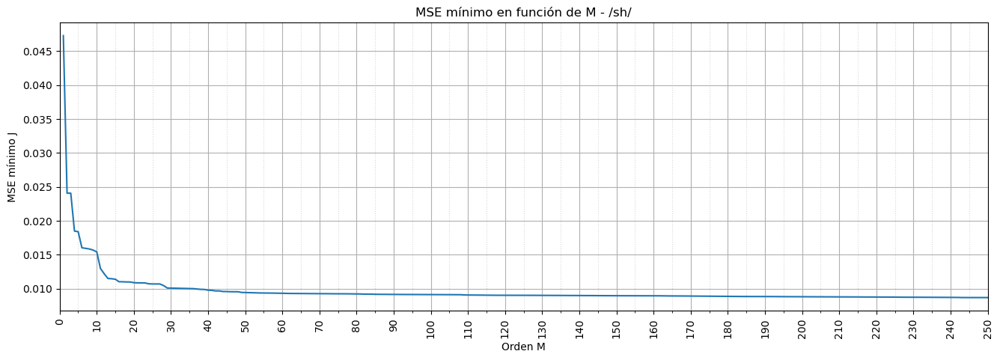

In [16]:
# CALCULAR J(M)
Mmax = 250

J_a = calcular_J(a,Mmax)
J_sh = calcular_J(sh,Mmax)

ordenes = np.arange( 1, Mmax + 1)

# GRÁFICA /a/
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(ordenes,J_a)
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE mínimo J")
ax.set_title( "MSE mínimo en función de M - /a/")
ax.set_xlim(0, Mmax)
ax.xaxis.set_major_locator(MultipleLocator(10))   # marca cada 10
ax.xaxis.set_minor_locator(MultipleLocator(5))    # marca menor cada 5
ax.grid(which="major")
ax.grid(which="minor", linestyle=":", alpha=0.5)
plt.xticks(rotation=90)
plt.show()

# GRÁFICA /sh/
fig, ax = plt.subplots(figsize=(16,5))
ax.plot(ordenes, J_sh)
ax.set_xlabel("Orden M")
ax.set_ylabel("MSE mínimo J")
ax.set_title("MSE mínimo en función de M - /sh/")
ax.set_xlim(0, Mmax)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(5))
ax.grid(which="major")
ax.grid(which="minor", linestyle=":", alpha=0.5)
plt.xticks(rotation=90)
plt.show()

## Señal de error en escala logarítmica (dB) para la identificación de puntos de inflexión
En la representación previa, la magnitud de la caída inicial impedía distinguir el segundo punto de inflexión del fonema «a», dado que su reducción de error es considerablemente menor. Por ello, se graficó la señal de error en decibelios (dB) para mejorar la resolución visual de ambos eventos. En esta nueva escala, se aprecia con claridad una segunda inflexión en la grabación de «a» en el intervalo $m \in [110, 120]$. Por el contrario, en la ampliación correspondiente a «sh» no se observa ninguna inflexión adicional, registrándose únicamente un decaimiento monótono del error.

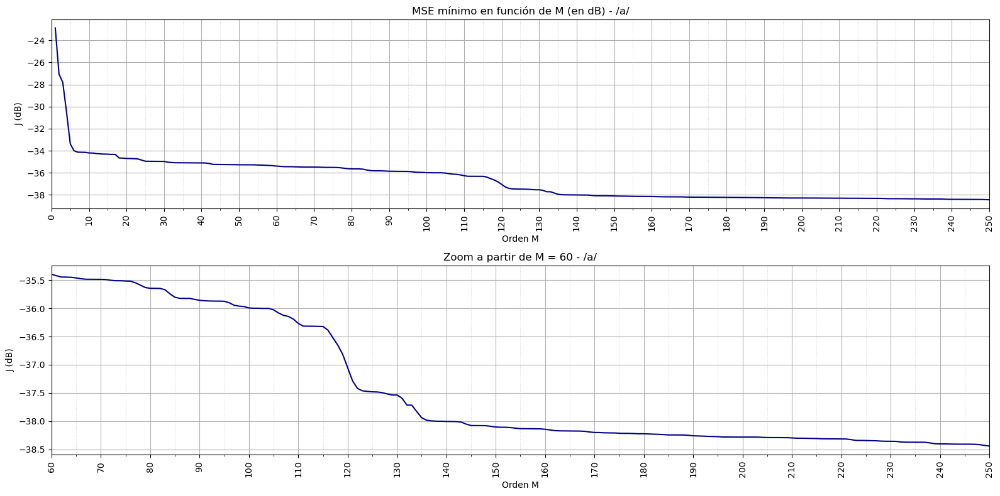

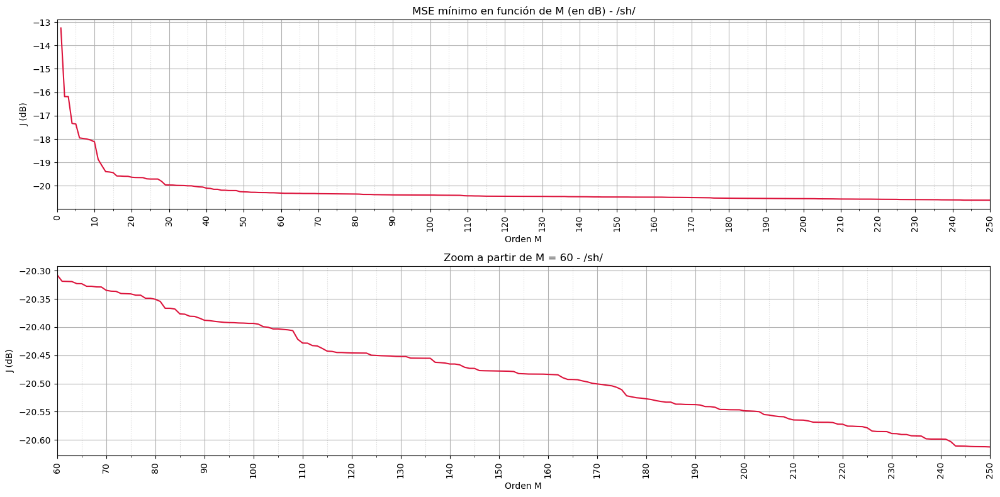

In [17]:
# J(M) EN dB PARA /a/ Y /sh/
J_a_dB = 10*np.log10(J_a)
J_sh_dB = 10*np.log10(J_sh)

def graficar_J_dB(M, J_dB, nombre, color, zoom_desde=60):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16,8))

    # Rango completo
    ax1.plot(M, J_dB, color=color)
    ax1.set_title(f"MSE mínimo en función de M (en dB) - {nombre}")
    ax1.set_ylabel("J (dB)")
    ax1.set_xlim(0, Mmax)

    # Zoom en la zona de M grandes (el eje y se ajusta solo a estos datos)
    zona = (M >= zoom_desde)
    ax2.plot(M[zona], J_dB[zona], color=color)
    ax2.set_title(f"Zoom a partir de M = {zoom_desde} - {nombre}")
    ax2.set_ylabel("J (dB)")
    ax2.set_xlim(zoom_desde, Mmax)

    for ax in (ax1, ax2):
        ax.set_xlabel("Orden M")
        ax.xaxis.set_major_locator(MultipleLocator(10))
        ax.xaxis.set_minor_locator(MultipleLocator(5))
        ax.grid(which="major")
        ax.grid(which="minor", linestyle=":", alpha=0.5)
        ax.tick_params(axis="x", rotation=90)

    plt.tight_layout()
    plt.show()

graficar_J_dB(ordenes, J_a_dB, "/a/", "navy")
graficar_J_dB(ordenes, J_sh_dB, "/sh/", "crimson")

## Análisis de la señal de error $e^f(n)$
La fase inicial consiste en implementar una función que compute la señal de error, recibiendo como parámetros de entrada la señal a evaluar y el orden del filtro correspondiente.

In [18]:
def calcular_predictor(x, M):
    N = len(x)

    # autocorrelación (lags 0..M)
    r = correlate(x, x, mode="full", method="fft")
    r = r[N-1:N+M] / N

    a = solve_toeplitz(r[:M], r[1:M+1])
    J = r[0] - np.dot(r[1:M+1], a)

    return a, J


def calcular_señal_de_error(x, M):

    a, _ = calcular_predictor(x, M)

    #creando la señal de error
    filtro_error = np.concatenate(([1], -a))
    e = lfilter(filtro_error, [1], x)

    return e

Posteriormente, se aplicó dicha función de cálculo del error hacia adelante sobre las señales correspondientes a los fonemas /a/ y /sh/, con el propósito de justificar la presencia de dos puntos de inflexión en lugar de uno (en contraste con lo sugerido en la consigna). Inicialmente, se analizó el comportamiento de la señal de error para distintos valores del orden de filtro $M$, evaluando su evolución antes, durante y después de cada punto de inflexión. Para determinar con precisión dichos valores de $M$, se emplearon las gráficas generadas previamente mediante herramientas de Python, las cuales optimizan la resolución y facilitan una lectura rigurosa de las coordenadas.

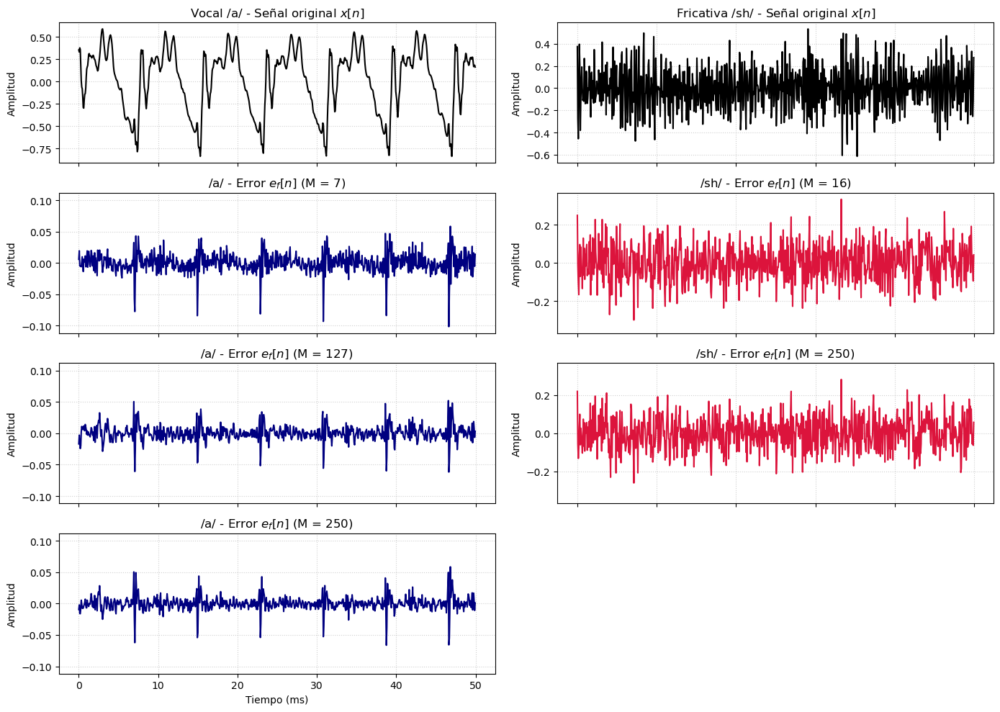

In [30]:
#estableciendo variables
inicio_tramo = 8000 # escogiendo un punto en el medio del segundo analizado
longitud = 800  # 50 ms
tiempo = np.arange(longitud) / fs * 1000 #ms

# Escogiendo diferentes M para el ruido /a/ para ver como cambia la señal de error dependiendo del codo
M_a_primer_codo = 7
M_a_segundo_codo = 127

# Lo mismo para /sh/
M_sh_primer_codo = 16

#ahora un M donde el error es mínimo para ambas señales
M_minimo = 250

tramo = slice(inicio_tramo, inicio_tramo + longitud)

# calculando la señal de error para /a/ con diferentes M (y recortando el tramo para graficar)
e_a_primer_codo = calcular_señal_de_error(a, M_a_primer_codo)[tramo]
e_a_segundo_codo = calcular_señal_de_error(a, M_a_segundo_codo)[tramo]
e_a_minimo = calcular_señal_de_error(a, M_minimo)[tramo]

# ahora haciendo lo mismo con la señal /sh/
e_sh_primer_codo = calcular_señal_de_error(sh, M_sh_primer_codo)[tramo]
e_sh_minimo = calcular_señal_de_error(sh, M_minimo)[tramo]

#escogiendo el tramo de audio para graficar
a_tramo = a[tramo]
sh_tramo = sh[tramo]

# graficando todo
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

# Columna de /a/
errores_a = [(M_a_primer_codo, e_a_primer_codo),
             (M_a_segundo_codo, e_a_segundo_codo),
             (M_minimo, e_a_minimo)]

axes[0, 0].plot(tiempo, a_tramo, color="black")
axes[0, 0].set_title("Vocal /a/ - Señal original $x[n]$")

for i, (M_i, e) in enumerate(errores_a):
    axes[i + 1, 0].plot(tiempo, e, color="navy")
    axes[i + 1, 0].set_title(f"/a/ - Error $e_f[n]$ (M = {M_i})")

# Columna de /sh/
errores_sh = [(M_sh_primer_codo, e_sh_primer_codo),
              (M_minimo, e_sh_minimo)]

axes[0, 1].plot(tiempo, sh_tramo, color="black")
axes[0, 1].set_title("Fricativa /sh/ - Señal original $x[n]$")

for i, (M_i, e) in enumerate(errores_sh):
    axes[i + 1, 1].plot(tiempo, e, color="crimson")
    axes[i + 1, 1].set_title(f"/sh/ - Error $e_f[n]$ (M = {M_i})")

# Mismo rango vertical para los errores de cada columna (así se compara la amplitud)
for col, errores in enumerate([errores_a, errores_sh]):
    ymax = max(np.max(np.abs(e)) for _, e in errores)
    for fila in range(1, 4):
        axes[fila, col].set_ylim(-1.1 * ymax, 1.1 * ymax)

for ax in axes.flatten():
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.set_ylabel("Amplitud")

axes[-1, 0].set_xlabel("Tiempo (ms)")
axes[-1, 1].set_xlabel("Tiempo (ms)")

axes[3, 1].axis("off")

plt.tight_layout()
plt.show()

N0 = 127 muestras = 7.94 ms  ->  f0 ≈ 126.0 Hz


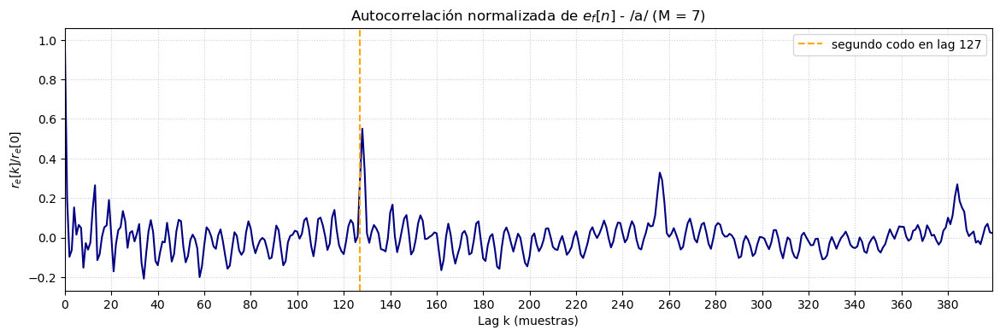

In [31]:
# graficando la autocorrelación de la señal de error para /a/ con M = 7

e = calcular_señal_de_error(a, M_a_primer_codo)[M_a_primer_codo:]     # sin el transitorio
e = e - np.mean(e)
r_e = correlate(e, e, mode="full", method="fft")
r_e = r_e[len(e)-1 : len(e)-1+400]
r_e = r_e / r_e[0]

# buscando el pico fuera de los primeros lags -> período de pitch
lag_min, lag_max = 60, 250   # equivale a buscar f0 entre 64 y 267 Hz
n0_estimado = M_a_segundo_codo  # Período de pitch asociado al segundo codo de J(M) (135 muestras)
print(f"N0 = {n0_estimado} muestras = {1000 * n0_estimado / fs:.2f} ms  ->  f0 ≈ {fs / n0_estimado:.1f} Hz")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(r_e, color="navy")
ax.axvline(n0_estimado, color="orange", linestyle="--", label=f"segundo codo en lag {n0_estimado}")
ax.set_title("Autocorrelación normalizada de $e_f[n]$ - /a/ (M = 7)")
ax.set_xlabel("Lag k (muestras)")
ax.set_ylabel("$r_e[k] / r_e[0]$")
ax.set_xlim(0, len(r_e) - 1)
ax.xaxis.set_major_locator(MultipleLocator(20))
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.show()


## Interpretación de los resultados

En primer lugar, se observa que la señal de error concentra su energía en las mismas regiones temporales donde la señal original presenta mayor actividad. Este comportamiento es esperable, ya que en los intervalos con mayor potencia el predictor lineal experimenta mayores desviaciones absolutas, incrementando consecuentemente la magnitud del error. Esta correspondencia confirma, de manera preliminar, el funcionamiento correcto de la rutina de cálculo del error.

Para el fonema /a/, la curva de error exhibe dos cambios de pendiente claramente diferenciados. El primero se manifiesta en órdenes reducidos, aproximadamente en el rango $M \approx 5$–$15$. Este primer punto de inflexión está asociado a la correlación a corto plazo de la señal de voz: con un número acotado de coeficientes, el predictor modela la envolvente espectral determinada por el tracto vocal y sus formantes.

Al examinar la señal de error correspondiente a este valor de $M$, se distingue una estructura semejante a un tren de pulsos con un espaciamiento aproximado de 7,8 ms. La amplitud de estos pulsos es considerable y persiste una notable fluctuación residual entre ellos, lo que evidencia un margen significativo de error no modelado.

Posteriormente, se aprecia una segunda inflexión en el entorno de $M \approx 110$–$130$. Dado el carácter cuasiperiódico de la vocal /a/, las muestras presentan alta correlación con aquellas distanciadas por un período fundamental (o de *pitch*). Cuando $M$ alcanza dicho retardo temporal, el filtro incorpora esta periodicidad a largo plazo, propiciando un nuevo descenso del error cuadrático medio (MSE), sutil en escala lineal pero nítido al representarse en decibelios (dB).

La señal de error para este orden superior evidencia dicha mejora: los pulsos observados previamente reducen sustancialmente su amplitud y el nivel de fluctuación entre crestas disminuye de forma drástica.

Este fenómeno se corrobora en la secuencia de autocorrelación graficada con anterioridad para $M = 12$. En ella se identifica un pico destacado para un retardo (*lag*) cercano a 127 muestras, acompañado de sus respectivos armónicos, coincidiendo de forma precisa con la posición del segundo punto de inflexión. Al poseer correlación periódica, la señal ofrece información redundante que el filtro solo logra explotar si su orden abarca dicho desfase. Así, al incrementar la memoria del predictor para alcanzar la correlación de tono, se produce una reducción adicional del error que da lugar al segundo codo.

$$N_0 \approx \frac{f_s}{f_0}$$

Asumiendo que la segunda inflexión se ubica en torno a $M \approx 127$ y con una frecuencia de muestreo $f_s = 16\,000\text{ Hz}$, la frecuencia fundamental estimada resulta:

$$f_0 \approx \frac{16\,000}{127} \approx 127\text{ Hz}$$

Este valor resulta plenamente consistente para una voz masculina sostenida.

De acuerdo con la literatura de referencia ([Voice frequency - Wikipedia](https://en.wikipedia.org/wiki/Voice_frequency)), la frecuencia fundamental de un varón adulto típico oscila entre 90 y 155 Hz, rango en el cual se inscribe nuestra muestra. Asimismo, fuentes biomédicas de los Institutos Nacionales de Salud ([PMC8478519](https://pmc.ncbi.nlm.nih.gov/articles/PMC8478519/)) reportan intervalos observados de 78 a 182 Hz para hablantes masculinos, validando experimentalmente el valor obtenido.

Por su parte, la señal correspondiente al fonema /sh/ presenta únicamente una inflexión en órdenes bajos. Este resultado concuerda con la naturaleza no sonora de la fricativa postalveolar: al carecer de excitación glótica periódica, no existe un componente de *pitch* que genere un segundo punto de inflexión.

El análisis temporal de la señal de error ratifica esta conclusión: no se advierte una estructura de pulsos periódicos, asemejándose a un proceso estocástico no correlacionado. Por lo tanto, al no existir redundancia periódica remota, el incremento en el orden del filtro no proporciona ventajas predictivas adicionales para este fonema.

# Parte 3: Respuesta en frecuencia del filtro del error de predicción

El tercer ejercicio emplea los coeficientes calculados por el predictor lineal; no obstante, el objetivo no es caracterizar el predictor en sí, sino evaluar la respuesta del filtro que genera el error de predicción.

## Predictor frente a filtro del error

El predictor lineal estima el valor actual de la señal $x[n]$ a partir de sus muestras pasadas:

$$\hat{x}[n] = a_1 x[n-1] + a_2 x[n-2] + \dots + a_M x[n-M]$$

Dado que el error de predicción hacia adelante se define como $e_f[n] = x[n] - \hat{x}[n]$, se obtiene:

* $$e_f[n] = x[n] - a_1 x[n-1] - a_2 x[n-2] - \dots - a_M x[n-M]$$



Esta operación equivale a procesar $x[n]$ mediante un filtro de respuesta al impulso finita (FIR) cuyo vector de coeficientes está dado por:

$$\bar{\mathbf{a}} = [1,\ -a_1,\ -a_2,\ \dots,\ -a_M]$$

Dicho sistema corresponde al filtro del error de predicción (o filtro de blanqueamiento). Su propósito es cancelar los componentes redundantes y predecibles de la señal de voz, generando como salida el residuo $e_f[n]$:

$$x[n] \;\longrightarrow\; \boxed{A(z)} \;\longrightarrow\; e_f[n]$$

## Justificación del análisis de $H(e^{j\omega})$

La respuesta en frecuencia describe la atenuación o ganancia que el filtro impone sobre cada componente espectral. Cuando la señal de voz exhibe resonancias marcadas (formantes) de alta previsibilidad, el filtro del error introduce valles espectrales en dichas frecuencias para atenuarlas en la señal residual. El objetivo teórico consiste en descorrelacionar la señal de entrada, aproximando el espectro del error al de un ruido blanco.

El procedimiento se evalúa para los órdenes $M \in \{1, 2, 4, 8, 16, 32, 64\}$, permitiendo constatar cómo la capacidad del sistema para modelar la envolvente espectral se incrementa en función del orden del filtro.

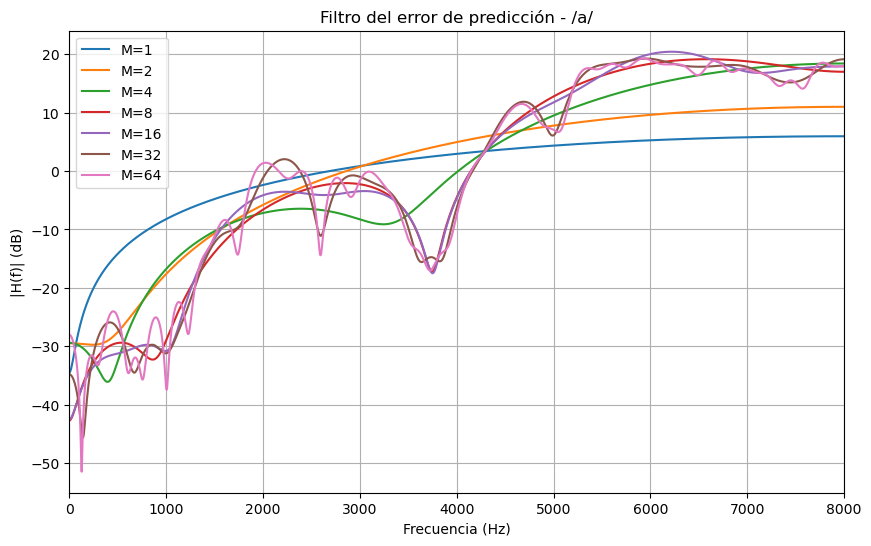

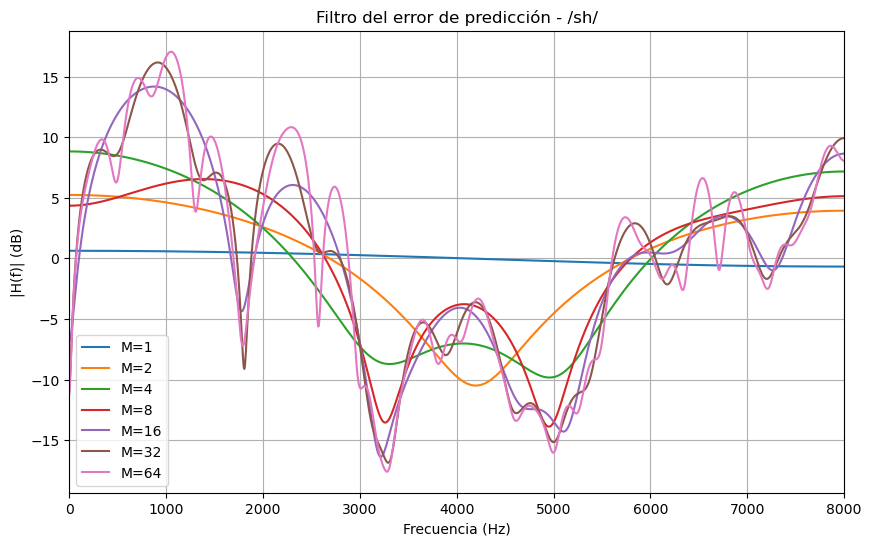

In [21]:
# VALORES DE M
valores_M = [1, 2, 4, 8, 16, 32, 64]

señales = {"/a/": a, "/sh/": sh}

for nombre, x in señales.items():

    plt.figure(figsize=(10,6))

    for M in valores_M:

        coef, _ = calcular_predictor(x, M)

        # FILTRO DEL ERROR
        filtro_error = np.concatenate(([1], -coef))

        f, H = freqz(filtro_error,worN=2048,fs=fs)

        plt.plot( f,20*np.log10(np.abs(H) + 1e-12),label=f"M={M}")

    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("|H(f)| (dB)")
    plt.title(f"Filtro del error de predicción - {nombre}")
    plt.xlim(0, fs/2)
    plt.legend()
    plt.grid()
    plt.show()

## Interpretación de las curvas

Para órdenes muy reducidos ($M = 1$ o $M = 2$), el filtro únicamente logra modelar una tendencia espectral elemental. La respuesta en frecuencia resultante presenta un perfil suave debido a la escasez de coeficientes para ajustar detalles finos.

Al incrementar el orden a $M \in \{4, 8, 16, 32, 64\}$, se configuran valles espectrales y fluctuaciones progresivamente más pronunciados. Esto evidencia que el sistema incorpora con mayor resolución la estructura espectral de cada fonema, suprimiendo de la señal residual las componentes de alta previsibilidad.

En el caso de /a/, al tratarse de un sonido sonoro, la respuesta en frecuencia exhibe una selectividad creciente determinada por su marcada estructura espectral (formantes) y temporal. En /sh/, el filtro modela su coloración espectral característica; no obstante, no se manifiestan componentes asociados a periodicidad de *pitch*, en concordancia con su naturaleza sorda.

La correspondencia con la función de costo $J(M)$ es directa: mientras el incremento de $M$ genere una reducción significativa de $J$, el aumento de orden estará capturando información estructural relevante. Cuando la curva de $J(M)$ alcanza una meseta asintótica, los órdenes superiores únicamente introducen ajustes marginales en $H(e^{j\omega})$, con un impacto prácticamente despreciable en la minimización del error global.

# Parte 4 (Comparado grabacion real con grabacion simulada)

Para la etapa de resíntesis se reutilizan las rutinas `calcular_predictor` y `calcular_señal_de_error` desarrolladas en el Punto 2, recargando los segmentos estacionarios de $1\text{ s}$ de **/a/** y **/sh/**.

In [22]:
# CARGAR /a/ Y /sh/ (el mismo segundo que en la parte 1)
a = cargar_audio(archivos["/a/"], inicio=inicios["/a/"])
sh = cargar_audio(archivos["/sh/"], inicio=inicios["/sh/"])

## Explicación del código

En primer término, se establecen órdenes de filtro $M$ diferenciados según la señal objeto de análisis. La consigna estipula seleccionar un orden $M$ correspondiente a la finalización del primer punto de inflexión. Dichos valores fueron determinados previamente en la Sección 2, donde se analizó la evolución del error en función de $M$ y se identificaron los puntos de corte para los fonemas /a/ y /sh/.

Posteriormente, la selección de la señal de excitación se fundamenta en las características del error residual graficado en la Sección 2.

Para el fonema /a/, la señal de error exhibe una estructura periódica equivalente a un tren de impulsos con un período fundamental $N_0 \approx 127$ muestras (acorde a lo discutido en el punto anterior). Para determinar la ganancia $g$ de cada impulso, se impone la condición de que la energía media por muestra iguale a la potencia del error $J$. Dado que se presenta un único impulso de energía $g^2$ cada $N_0$ muestras:

$$\frac{g^2}{N_0} = J$$

Despejando la amplitud de excitación:

$$g = \sqrt{J \cdot N_0}$$

Por el contrario, el residuo correspondiente al fonema /sh/ presenta características puramente estocásticas (conforme a las gráficas de la Sección 2), por lo que se modela mediante ruido blanco gaussiano escalado para satisfacer una varianza igual a $J$.

Finalmente, la rutina implementa el filtrado inverso (filtro de síntesis) excitado por estas fuentes sintéticas para reconstruir las señales vocales correspondientes.

In [34]:
# definiendo variables
M_a = 7
M_sh = 16
n0 = n0_estimado  # período de pitch correspondiente al segundo codo (135 muestras)
print("n0 =", n0)

N_a = len(a)
N_sh = len(sh)
rng = np.random.default_rng(0)  # semilla fija para que los resultados se puedan repetir

# Calculando los coeficientes del predictor y el MSE mínimo J para /a/ y /sh/
a_coef, J_a_pred = calcular_predictor(a, M_a)
sh_coef, J_sh_pred = calcular_predictor(sh, M_sh)

g = np.sqrt(J_a_pred * n0)
h = np.sqrt(J_sh_pred)

#creando las señales de excitacion
a_exc = np.zeros(N_a)
a_exc[::n0] = -g  # un impulso de amplitud g cada n0 muestras (negativo, como los pulsos del error real)
sh_exc = rng.standard_normal(N_sh) * h

# chequeo: la energía por muestra de la excitación tiene que ser parecida a J
print(np.mean(a_exc**2), J_a_pred)
print(np.mean(sh_exc**2), J_sh_pred)

#ahora utilizando los coeficientes del predictor en inversa para producir la señal sintetizada
a_sint = lfilter([1], np.concatenate(([1], -a_coef)), a_exc)
sh_sint = lfilter([1], np.concatenate(([1], -sh_coef)), sh_exc)

# chequeo: la potencia de la señal sintetizada tiene que ser parecida a la original
print(np.mean(a_sint**2), np.mean(a**2))
print(np.mean(sh_sint**2), np.mean(sh**2))

# guardando los audios (normalizados para que no haya clipping)
def guardar_audio(nombre, y):
    y = y / np.max(np.abs(y))
    wavfile.write(DIR_SINTETIZADAS / nombre, fs, (y * 32767).astype(np.int16))

guardar_audio("a_sintetizada.wav", a_sint)
guardar_audio("sh_sintetizada.wav", sh_sint)

# escuchando original vs sintetizada
for nombre, original, sintetizada in [("/a/", a, a_sint), ("/sh/", sh, sh_sint)]:
    print(f"{nombre} original:")
    ipd.display(ipd.Audio(original, rate=fs))
    print(f"{nombre} sintetizada:")
    ipd.display(ipd.Audio(sintetizada, rate=fs))

n0 = 127
0.0003859753810634322 0.0003859271401709108
0.01095952718866971 0.01101840791321479
0.14129747853807936 0.13821795588261768
0.045908018347189834 0.04754316873672324
/a/ original:


/a/ sintetizada:


/sh/ original:


/sh/ sintetizada:


A continuación se representan en los dominios temporal y espectral las excitaciones reales vs. modeladas, y las señales originales vs. sintetizadas.

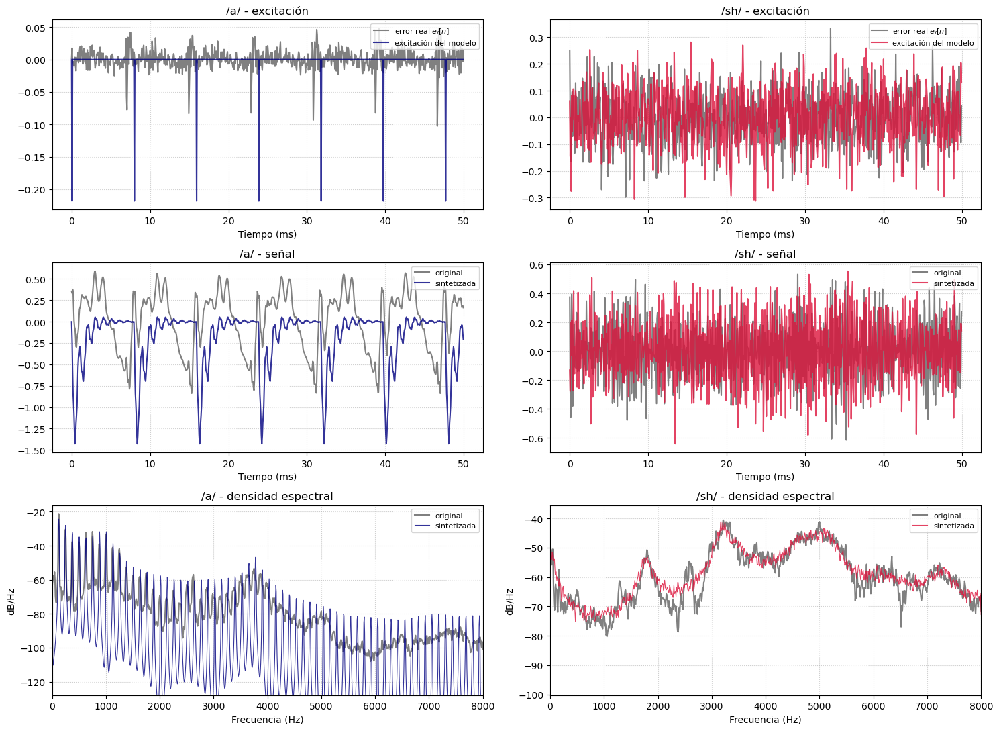

In [33]:
e_a_real = calcular_señal_de_error(a, M_a)
e_sh_real = calcular_señal_de_error(sh, M_sh)

fig, axes = plt.subplots(3, 2, figsize=(15, 11))

for col, (nombre, x, x_sint, e_real, exc, color) in enumerate([
        ("/a/", a, a_sint, e_a_real, a_exc, "navy"),
        ("/sh/", sh, sh_sint, e_sh_real, sh_exc, "crimson")]):

    # excitación real vs modelo
    ax = axes[0, col]
    ax.plot(tiempo, e_real[tramo], color="gray", label="error real $e_f[n]$")
    ax.plot(tiempo, exc[tramo], color=color, alpha=0.8, label="excitación del modelo")
    ax.set_title(f"{nombre} - excitación")
    ax.set_xlabel("Tiempo (ms)")

    # señal original vs sintetizada
    ax = axes[1, col]
    ax.plot(tiempo, x[tramo], color="gray", label="original")
    ax.plot(tiempo, x_sint[tramo], color=color, alpha=0.8, label="sintetizada")
    ax.set_title(f"{nombre} - señal")
    ax.set_xlabel("Tiempo (ms)")

    # espectros
    ax = axes[2, col]
    f, P = welch(x, fs=fs, nperseg=2048)
    f, P_sint = welch(x_sint, fs=fs, nperseg=2048)
    ax.plot(f, 10*np.log10(P), color="gray", label="original")
    ax.plot(f, 10*np.log10(P_sint), color=color, alpha=0.8, lw=0.8, label="sintetizada")
    ax.set_xlim(0, fs/2)
    # la sintetizada de /a/ tiene rayas perfectas y casi nada entre ellas, limitamos el eje y
    ax.set_ylim(10*np.log10(P).min() - 20, 10*np.log10(P).max() + 5)
    ax.set_title(f"{nombre} - densidad espectral")
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("dB/Hz")

for ax in axes.flatten():
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## Discusión de resultados

Al comparar la señal sintetizada con la grabación real del fonema /a/, se percibe una cualidad marcadamente artificial o «robótica» en la versión generada. Como se evidencia en el gráfico superior izquierdo («/a/ - excitación»), esta discrepancia radica en que el modelo de excitación adoptado emplea exclusivamente un tren de pulsos ideales (trazo azul), omitiendo el componente de ruido estocástico interpulso y las fluctuaciones inherentes al error real (trazo gris). En consecuencia, en la forma de onda resultante («/a/ - señal») se suprimen los rasgos de naturalidad de la grabación original, conservándose únicamente la respuesta periódica del tracto vocal asociada a la vocal /a/ (cuya coincidencia de envolvente y estructura armónica se corrobora en la gráfica de densidad espectral inferior).

Específicamente, la simplificación de la fuente de excitación artificial respecto al residuo de predicción exacto introduce pérdidas notorias:

En primer lugar, de acuerdo con la literatura sobre procesamiento de voz ([Speech Processing Book - Jitter and Shimmer](https://speechprocessingbook.aalto.fi/representations/jitter-and-shimmer)), la voz humana presenta *jitter*, entendido como pequeñas variaciones estocásticas en la duración del período fundamental entre ciclos glóticos sucesivos. Por el contrario, como se aprecia en el tren de impulsos del gráfico de excitación de /a/, la fuente implementada para el filtrado inverso impone un período de *pitch* estrictamente constante a lo largo de toda la síntesis.

En segundo lugar, el residuo glótico natural manifiesta fluctuaciones ciclo a ciclo en la amplitud de los picos de excitación, fenómeno denominado *shimmer* ([Speech Processing Book - Jitter and Shimmer](https://speechprocessingbook.aalto.fi/representations/jitter-and-shimmer)), el cual contrasta en la figura con la amplitud uniforme del tren de pulsos sintético.

Finalmente, se asume un modelo lineal e invariante en el tiempo para la totalidad del segmento analizado, condición teórica que difiere de la imposibilidad fisiológica de un hablante para sostener un tono y una configuración articular con perfecta invariabilidad temporal.

A pesar de estas limitaciones, la señal sintetizada preserva una notable fidelidad tímbrica respecto al fonema /a/, permitiendo su clara e inequívoca inteligibilidad fonética.

Por el contrario, como se observa en los paneles de la columna derecha correspondientes a /sh/, tanto el error residual real como la excitación del modelo («/sh/ - excitación») presentan un comportamiento puramente estocástico equivalente a ruido blanco. Debido a esta ausencia de estructura periódica, la señal sintetizada en el dominio temporal («/sh/ - señal») se asemeja igualmente a una realización aleatoria cuyos rasgos espectrales («/sh/ - densidad espectral») replican la envolvente del sonido original, sin que pueda discernirse un tono o estructura temporal determinista particular.

## Modificación del modelo de síntesis

A partir de la revisión teórica sobre la fonación humana y la consideración de parámetros estocásticos como el *jitter* y el *shimmer*, se implementó una rutina de excitación modificada. Esta variante introduce perturbaciones controladas (dentro de acotados márgenes de tolerancia) tanto en la duración del período fundamental como en las amplitudes de los impulsos, con el propósito de aproximar la señal simulada a la variabilidad natural del fonema /a/. Asimismo, se incorporó una componente de ruido aleatorio superpuesta entre los pulsos glóticos, reproduciendo de este modo el componente estocástico propio del residuo real.

In [25]:
# definiendo variables
M_a = 7
n0 = n0_estimado

jitter = 0.02  # variación del período entre pulsos (desvío estándar, como fracción de n0)
shimmer = 0.2  # variación de la amplitud de cada pulso (desvío estándar, como fracción de g)
ruido_rel = 0.1  # fracción de la energía de la excitación que se le da al ruido

N_a = len(a)
rng = np.random.default_rng(0)  # semilla fija para que los resultados se puedan repetir

# Calculando los coeficientes del predictor y el MSE mínimo J para /a/
a_coef, J_a_pred = calcular_predictor(a, M_a)

g = np.sqrt(J_a_pred * (1 - ruido_rel) * n0)  # amplitud base de cada impulso

#creando la excitacion: impulsos con jitter y shimmer
impulsos = np.zeros(N_a)
pos = 0.0
while pos < N_a:
    impulsos[int(pos)] = -g * (1 + shimmer * rng.standard_normal())  # amplitud variable (negativo, como en el error real)
    pos += n0 * (1 + jitter * rng.standard_normal())  # período variable

# ajustando la energía de los impulsos para que coincida con la parte de J que les corresponde
impulsos *= np.sqrt(J_a_pred * (1 - ruido_rel) / np.mean(impulsos**2))

# ruido blanco gaussiano de fondo
ruido = rng.standard_normal(N_a) * np.sqrt(J_a_pred * ruido_rel)

a_exc_humana = impulsos + ruido

# chequeo: la energía por muestra de la excitación tiene que ser parecida a J
print(np.mean(a_exc_humana**2), J_a_pred)

#ahora utilizando los coeficientes del predictor en inversa para producir la señal sintetizada
a_sint_humana = lfilter([1], np.concatenate(([1], -a_coef)), a_exc_humana)

# chequeo: la potencia de la señal sintetizada tiene que ser parecida a la original
print(np.mean(a_sint_humana**2), np.mean(a**2))

# guardando el audio (usa la función guardar_audio de antes)
guardar_audio("a_sintetizada_humana.wav", a_sint_humana)

print("/a/ original:")
ipd.display(ipd.Audio(a, rate=fs))
print("/a/ sintetizada (período constante):")
ipd.display(ipd.Audio(a_sint, rate=fs))
print("/a/ sintetizada con jitter, shimmer y ruido:")
ipd.display(ipd.Audio(a_sint_humana, rate=fs))

0.00038623698504092923 0.0003859271401709108
0.13821507771383823 0.13821795588261768
/a/ original:


/a/ sintetizada (período constante):


/a/ sintetizada con jitter, shimmer y ruido:


Tras evaluar diferentes configuraciones de jitter, shimmer y ruido estocástico, se constata una mejora audible en la calidad de la señal sintetizada, atenuando su aspereza y el carácter marcadamente artificial inicial. No obstante, la emisión continúa exhibiendo una naturaleza sintética, distante de la complejidad de una voz humana real. Dicha limitación obedece a que el modelado del error mediante formulaciones matemáticas elementales carece de la precisión necesaria para replicar con exactitud el residuo real y conferirle una naturalidad óptima.

# Parte 5 (Grabacion Sintetizada)

Para procesar una señal de habla continua donde el tracto vocal varía en el tiempo, se implementa un vocoder LPC por bloques con el método de *Overlap-Add* (OLA):

* **Segmentación:** Bloques de $L = 50\text{ ms}$ ($800$ muestras) con ventana de Hann periódica y $50\%$ de solapamiento ($\text{hop} = 400$ muestras).
* **Predicción:** Coeficientes de predicción lineal con orden fijo $M = 12$ por bloque (especificado por la consigna para modelar la envolvente espectral).
* **Excitación:** Tren de impulsos periódico a $f_0 = 160\text{ Hz}$ ($P = 100$ muestras), generado sobre una grilla temporal global para garantizar coherencia de fase entre bloques.
* **Síntesis y recombinación:** Filtrado todo-polo $1/A_i(z)$, reventaneo con Hann y superposición temporal acumulativa (OLA).

In [26]:
# Cargando el audio de voz libre
grab_libre = cargar_audio(DIR_GRABACIONES / "long_rec_16k.wav", duracion=None)  # duracion=None para no limitar la duración

# Definiendo los parametros
fs = 16000
L = int(0.05 * fs)  # 50 ms -> 800 muestras
hop = L // 2  # cuanto avanza la ventana de bloque a bloque (overlap del 50 %)
M = 12
P = fs // 160  # Período (pero en samples no por segundos) -> 100 muestras
N = len(grab_libre)
cantidad_bloques = (N - L) // hop + 1 # Cantidad de bloques que entran en la señal de largo N

ventana = windows.hann(L, sym=False)

# chequeo: con 50 % de overlap las ventanas de Hann suman 1
suma_ventanas = np.zeros(N)
for i in range(cantidad_bloques):
    suma_ventanas[i * hop:i * hop + L] += ventana
print("Suma de ventanas (lejos de los bordes): min =", suma_ventanas[L:-L].min(), " max =", suma_ventanas[L:-L].max())

# creando el tren de impulsos fuera del bucle
tren_impulsos = np.zeros(N)
tren_impulsos[::P] = 1
voz_sint = np.zeros(N) # variable para señal sintetizada
picos_bloques = np.zeros(cantidad_bloques)  # pico de cada bloque sintetizado (para analizar después)
polo_max = np.zeros(cantidad_bloques)       # módulo del polo más cercano a la circunferencia unidad

# Trabajando bloque a bloque
for i in range(cantidad_bloques):
    bloque = grab_libre[i * hop:i * hop + L]
    bloque_modificado = bloque * ventana  # Aplicando ventana de Hann
    r = np.array([np.dot(bloque_modificado[:L-k], bloque_modificado[k:]) for k in range(M+1)]) # calcula la auto a mano (bastante ineficiente, pero para 12 lags funciona bien)
    if r[0] == 0:  # bloque de silencio digital: no hay nada que predecir
        continue
    coeficientes = solve_toeplitz(r[:M], r[1:M+1])

    # Filtrando el tren de impulsos con los coeficientes obtenidos
    filtro_error = np.concatenate(([1], -coeficientes))
    excitacion = tren_impulsos[i * hop:i * hop + L]
    bloque_sintetizado = lfilter([1], filtro_error, excitacion)
    bloque_sintetizado *= ventana
    voz_sint[i * hop:i * hop + L] += bloque_sintetizado

    picos_bloques[i] = np.max(np.abs(bloque_sintetizado))
    polo_max[i] = np.max(np.abs(np.roots(filtro_error)))

# Normalizando la señal sintetizada
voz_sint /= np.max(np.abs(voz_sint))

# Guardando la señal sintetizada
wavfile.write(DIR_SINTETIZADAS / "voz_sintetizada.wav", fs, (voz_sint * 32767).astype(np.int16))

print("Grabación original:")
ipd.display(ipd.Audio(grab_libre, rate=fs))
print("Voz sintetizada:")
ipd.display(ipd.Audio(voz_sint, rate=fs))

Suma de ventanas (lejos de los bordes): min = 0.9999999999999996  max = 1.0000000000000002


Grabación original:


Voz sintetizada:


## Diagnóstico del resultado: 
Hay un problema, que el audio de la 'voz_sint' generada del procedimiento anterior básicamente no se escucha nada, la señal es inaudible.

Para intentar encontrar la razón de esto, se analizó la amplitud pico producida por cada bloque antes de la normalización global y la ubicación de los polos del filtro de síntesis \(1/A(z)\):

In [27]:
# Diagnóstico: ¿qué bloques fijan el pico máximo que comprime la normalización?
for i in np.argsort(picos_bloques)[::-1][:4]:
    print(f"Bloque {i:4d} (t = {i * hop / fs:6.3f} s): pico = {picos_bloques[i]:10.1f}   polo más cercano a |z|=1: {polo_max[i]:.5f}")
print(f"Mediana de los picos en los restantes bloques: {np.median(picos_bloques):.1f}")

# La grabación comienza con un intervalo constante de silencio digital previo a la fonación
inicio_constante = np.argmax(np.diff(grab_libre) != 0) + 1
print(f"Las primeras {inicio_constante} muestras ({1000 * inicio_constante / fs:.0f} ms) corresponden a valores constantes")

# Misma síntesis, pero re-normalizada omitiendo dicho tramo inicial espurio
voz_sint_sin_inicio = voz_sint.copy()
voz_sint_sin_inicio[:inicio_constante] = 0
voz_sint_sin_inicio /= np.max(np.abs(voz_sint_sin_inicio))
print("\nVoz sintetizada (impulsos de amplitud unitaria), re-normalizada sin el tramo inicial:")
ipd.display(ipd.Audio(voz_sint_sin_inicio, rate=fs))

Bloque    0 (t =  0.000 s): pico =   128935.4   polo más cercano a |z|=1: 0.99865
Bloque    1 (t =  0.025 s): pico =   128935.4   polo más cercano a |z|=1: 0.99865
Bloque  572 (t = 14.300 s): pico =       80.0   polo más cercano a |z|=1: 0.97985
Bloque    4 (t =  0.100 s): pico =       72.0   polo más cercano a |z|=1: 0.99775
Mediana de los picos en los restantes bloques: 6.5
Las primeras 1479 muestras (92 ms) corresponden a valores constantes

Voz sintetizada (impulsos de amplitud unitaria), re-normalizada sin el tramo inicial:


### Justificación física y matemática del silencio observado

El diagnóstico revela dos problemas fundamentales:

1. **Inestabilidad numérica por el silencio digital inicial:**
   Las primeras $1479$ muestras ($\approx 92\text{ ms}$) del archivo corresponden a silencio digital absoluto ($x[n] = 0$). Al restar la media en `cargar_audio`, este tramo se convierte en una señal estrictamente constante no nula. Para una señal constante, el mejor predictor es $\hat{x}[n] = x[n-1]$ ($a_1 \approx 1$), por lo que $A(z)$ ubica una raíz sobre el círculo unitario en $z \approx 1$ ($|z| \approx 0{,}99865$). El filtro de síntesis todo-polo $1/A(z)$ posee allí una ganancia resonante desmedida ($\approx 128\,900$). Al normalizar la señal completa dividiendo por el valor pico global, todo el habla posterior queda atenuada por un factor de $20\,000$, resultando imperceptible.
   
2. **Ausencia de control de ganancia local:**
   Aun renormalizando sin ese artefacto inicial (`voz_sint_sin_inicio`), la excitación con impulsos de amplitud unitaria fija ($1$) no transmite la dinámica de la voz original: las pausas, sílabas suaves y vocales abiertas reciben la misma excitación, y la energía de salida queda sujeta exclusivamente a las fluctuaciones de ganancia del filtro $1/A_i(z)$.

### Compensación de energía: Síntesis con ganancia adaptativa por bloque

Para resolver ambos problemas y reconstruir la señal con su envolvente de volumen natural (siguiendo el mismo principio de conservación energética formulado en el Punto 4), se modula la amplitud del tren de impulsos en cada bloque según el error cuadrático medio local $J_i$:

$$g_i = \sqrt{J_i \cdot P}$$

donde $J_i = \frac{1}{L}\left(r_i[0] - \mathbf{p}_i^T \mathbf{a}_i\right)$ es la potencia del residuo de predicción del bloque y $P = 100$ muestras es el período de la excitación ($160\text{ Hz}$). Con este escalamiento, los bloques de silencio o ruido de fondo producen $g_i \approx 0$ (evitando la amplificación de polos espurios), y las tramas vocálicas reciben la energía que les corresponde.

In [28]:
voz_sint_g = np.zeros(N) # señal sintetizada con ganancia adaptativa por bloque
ganancias = np.zeros(cantidad_bloques)

for i in range(cantidad_bloques):
    bloque = grab_libre[i * hop:i * hop + L]
    bloque_modificado = bloque * ventana
    r = np.array([np.dot(bloque_modificado[:L-k], bloque_modificado[k:]) for k in range(M+1)])
    if r[0] == 0:
        continue
    coeficientes = solve_toeplitz(r[:M], r[1:M+1])

    # MSE mínimo del bloque (por muestra) y ganancia de los impulsos: g^2 / P = J
    J_bloque = (r[0] - np.dot(r[1:M+1], coeficientes)) / L
    ganancias[i] = np.sqrt(J_bloque * P)

    filtro_error = np.concatenate(([1], -coeficientes))
    excitacion = ganancias[i] * tren_impulsos[i * hop:i * hop + L]
    bloque_sintetizado = lfilter([1], filtro_error, excitacion)
    bloque_sintetizado *= ventana
    voz_sint_g[i * hop:i * hop + L] += bloque_sintetizado

voz_sint_g /= np.max(np.abs(voz_sint_g))
wavfile.write(DIR_SINTETIZADAS / "voz_sintetizada_ganancia.wav", fs, (voz_sint_g * 32767).astype(np.int16))

print("Grabación original:")
ipd.display(ipd.Audio(grab_libre, rate=fs))
print("Voz sintetizada (impulsos unitarios, re-normalizada sin transitorio inicial):")
ipd.display(ipd.Audio(voz_sint_sin_inicio, rate=fs))
print("Voz sintetizada (con ganancia adaptativa por bloque):")
ipd.display(ipd.Audio(voz_sint_g, rate=fs))

Grabación original:


Voz sintetizada (impulsos unitarios, re-normalizada sin transitorio inicial):


Voz sintetizada (con ganancia adaptativa por bloque):


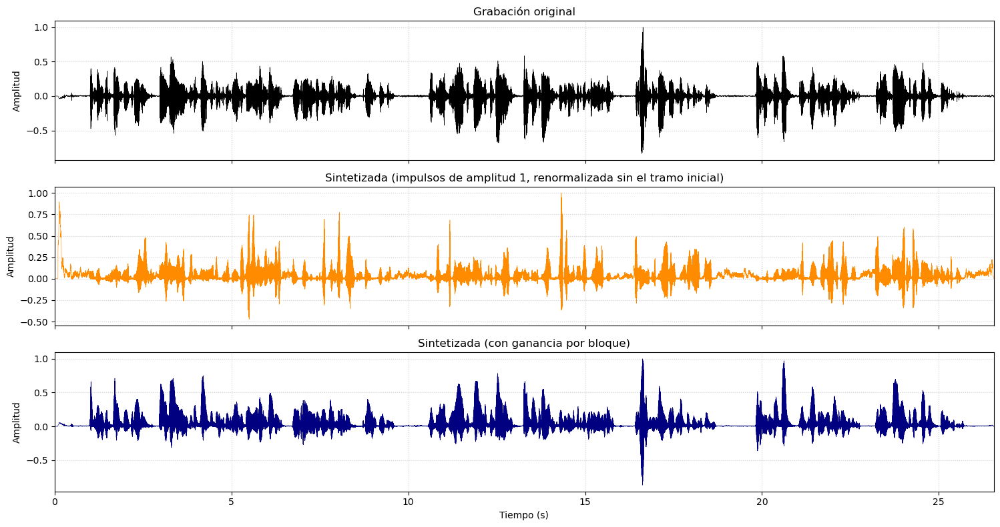

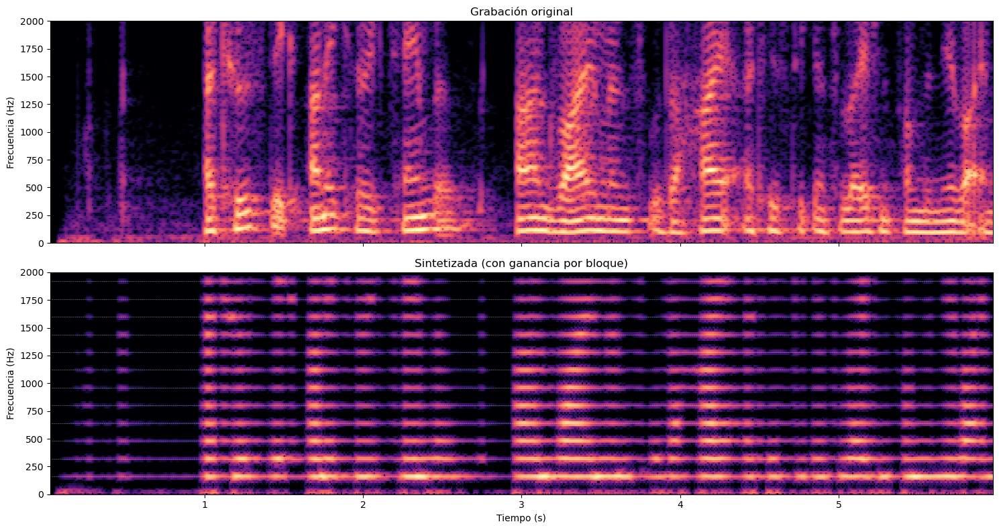

In [29]:
# Comparando en el tiempo y con espectrogramas
t = np.arange(N) / fs

fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
for ax, (titulo, s, color) in zip(axes, [("Grabación original", grab_libre, "black"),
                                         ("Sintetizada (impulsos de amplitud 1, renormalizada sin el tramo inicial)", voz_sint_sin_inicio, "darkorange"),
                                         ("Sintetizada (con ganancia por bloque)", voz_sint_g, "navy")]):
    ax.plot(t, s, color=color, lw=0.4)
    ax.set_title(titulo)
    ax.set_ylabel("Amplitud")
    ax.grid(True, linestyle=":", alpha=0.6)
axes[-1].set_xlabel("Tiempo (s)")
axes[-1].set_xlim(0, t[-1])
plt.tight_layout()
plt.show()

# Espectrogramas de los primeros segundos (zoom 0-2 kHz para ver los armónicos del pitch)
t_max = 6  # s
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, (titulo, s) in zip(axes, [("Grabación original", grab_libre),
                                  ("Sintetizada (con ganancia por bloque)", voz_sint_g)]):
    f_s, t_s, S = spectrogram(s[:t_max * fs], fs=fs, window="hann", nperseg=1024, noverlap=896)
    S_dB = 10 * np.log10(S + 1e-12)
    ax.pcolormesh(t_s, f_s, S_dB, shading="auto", cmap="magma", vmin=S_dB.max() - 70, vmax=S_dB.max())
    if "Sintetizada" in titulo:
        for k in range(1, 13):
            ax.axhline(160 * k, color="white", lw=0.4, ls=":")  # múltiplos de 160 Hz
    ax.set_ylim(0, 2000)
    ax.set_ylabel("Frecuencia (Hz)")
    ax.set_title(titulo)
axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

## Discusión y Conclusiones del Vocoder LPC

Al reproducir la señal resintetizada mediante el vocoder con ganancia adaptativa y compararla con el registro original, el mensaje en sí más o menos se puede entender (algunas palabras se entienden y, si escuchas el mensaje original y después el robótico, se entiende todo). Entonces, si sabes qué esperar (escuchaste el mensaje), la voz sintética se entiende mucho mejor, pero si no, a veces la voz sintética produce ruidos que son complicados de entender. Esto se debe a varias razones, que se explican a continuación:

1. **Preservación de la inteligibilidad (Evolución de formantes):** El filtro $1/A_i(z)$ de orden $M = 12$ estimado en ventanas de $50\text{ ms}$ captura razonablemente bien la trayectoria temporal de las frecuencias formánticas, que constituyen las claves acústicas esenciales para la diferenciación fonética de las palabras. En el espectrograma se comprueba que las concentraciones de energía coinciden en tiempo y frecuencia con las de la grabación original. En consecuencia, los sonidos de la voz sintética son similares a los de la voz real.

2. **Pérdida de entonación y efecto monótono:** La señal original exhibe una frecuencia fundamental continuamente modulada por la prosodia, que sube y baja entre $100$ y $130\text{ Hz}$, con sus armónicos acompañando esa variación. Al sustituir la excitación glotal real por un tren de impulsos periódico fijo a $160\text{ Hz}$, los armónicos en el espectrograma colapsan en líneas horizontales perfectamente rígidas en múltiplos de $160\text{ Hz}$. La pérdida de la curva de tono elimina toda inflexión expresiva, confiriendo a la voz una altura tonal artificialmente más aguda y monótona. Esto en parte hace que sea más difícil de entender.

3. **Tratamiento inadecuado de segmentos no sonoros:** El sistema excita todos los bloques mediante impulsos periódicos, independientemente de la naturaleza acústica de la trama. Durante consonantes fricativas (/s/, /sh/) y oclusivas (/t/), en lugar de generarse un espectro continuo de ruido, se excitan armónicos discretos que producen un zumbido sintético.

4. **Pérdida de los detalles de la excitación real:** El error de predicción real tiene pulsos de amplitud variable (shimmer), períodos que cambian levemente entre ciclos (jitter) y ruido entre pulsos. El tren de impulsos fijo no tiene nada de esto, por lo que la voz suena robótica incluso en los tramos donde el filtro captura bien las formantes. De nuevo, esta falta de aspectos presentes en la voz humana hace que sea más complicado entender el tramo por completo.

5. **Resolución temporal de la ventana:** Cada filtro se estima con $50\text{ ms}$ de señal y se mantiene fijo en ese bloque, por lo que los cambios rápidos (transiciones entre fonemas, la explosión de /t/) quedan suavizados. En codificación de voz es habitual usar bloques más cortos, pero a costa de una peor estimación del filtro.